# Per-RX KPI variation across traffic classes

**Scenario:** `intersection_nlosv.mob.csv` (9-vehicle L-shaped platoon) with `V2V_Highway` pathloss + geometric NLOSv overlay (`ThreeGppGeometricNlosvModel`).
Only the leader (node 0) transmits; nodes 1..8 receive.
PHY/MAC fixed at MCS 14, bwPRBs 10, HARQ on, PSFCH=4, maxNumTx=2.

**Inputs:** the four tidy CSVs produced by `extract_kpis.py` after running `run_traffic_class_campaign.sh`.

## 1. Setup

In [11]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

RESULTS = Path('results_traffic_class_eval')
TIDY    = RESULTS / 'tidy'

CLASS_ORDER = ['periodic1','periodic2','periodic3','aperiodic1','aperiodic2']
CLASS_COLORS = {
    'periodic1':  '#2c7bb6',
    'periodic2':  '#abd9e9',
    'periodic3':  '#d7191c',
    'aperiodic1': '#fdae61',
    'aperiodic2': '#7b3294',
}

def order_class(df):
    df = df.copy()
    df['trafficClass'] = pd.Categorical(df['trafficClass'], CLASS_ORDER, ordered=True)
    return df.sort_values('trafficClass')

rx = order_class(pd.read_csv(TIDY / 'per_rx_kpis.csv'))
ts = order_class(pd.read_csv(TIDY / 'time_series.csv'))
ru = order_class(pd.read_csv(TIDY / 'resource_usage.csv'))
hq = order_class(pd.read_csv(TIDY / 'harq_stats.csv'))

print(f'per_rx_kpis    : {len(rx)} rows  classes={rx.trafficClass.unique().tolist()}  seeds/class={rx.groupby("trafficClass").seed.nunique().to_dict()}')
print(f'time_series    : {len(ts)} rows  time-bins/run={ts.t_bin_s.nunique()}')
print(f'resource_usage : {len(ru)} rows  grants/run mean={ru.groupby(["trafficClass","seed"]).size().mean():.0f}')
print(f'harq_stats     : {len(hq)} rows')

per_rx_kpis    : 800 rows  classes=['periodic1', 'periodic2', 'periodic3', 'aperiodic1', 'aperiodic2']  seeds/class={'periodic1': 20, 'periodic2': 20, 'periodic3': 20, 'aperiodic1': 20, 'aperiodic2': 20}
time_series    : 38810 rows  time-bins/run=61
resource_usage : 555164 rows  grants/run mean=5783
harq_stats     : 100 rows


## 2. Per-RX distributions of PRR, PIR, throughput

Each box shows the distribution across (RX node × seed) for one traffic class. Black dots are raw points.

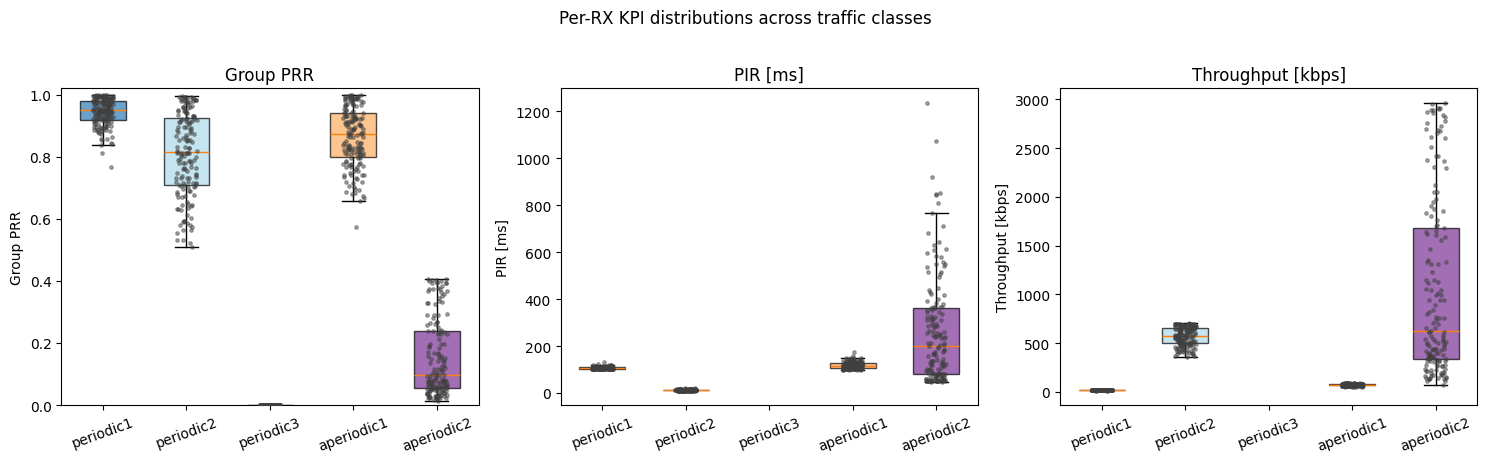

In [12]:
classes = [c for c in CLASS_ORDER if c in rx.trafficClass.unique()]
metrics = [('prr', 'Group PRR', (0, 1.02)),
           ('pir_ms', 'PIR [ms]', None),
           ('tput_kbps', 'Throughput [kbps]', None)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, label, ylim) in zip(axes, metrics):
    data_lst = [rx[rx.trafficClass == c][col].dropna().to_numpy() for c in classes]
    bp = ax.boxplot(data_lst, patch_artist=True, tick_labels=classes,
                    widths=0.55, showfliers=False)
    for box, c in zip(bp['boxes'], classes):
        box.set_facecolor(CLASS_COLORS[c]); box.set_alpha(0.7)
    for i, c in enumerate(classes, 1):
        vals = rx[rx.trafficClass == c][col].dropna().to_numpy()
        jitter = (np.random.rand(len(vals)) - 0.5) * 0.25
        ax.scatter(np.full_like(vals, i, dtype=float) + jitter, vals,
                   s=6, color='0.25', alpha=0.45, zorder=3)
    ax.set_ylabel(label); ax.set_title(label)
    if ylim: ax.set_ylim(ylim)
    for t in ax.get_xticklabels(): t.set_rotation(20)
fig.suptitle('Per-RX KPI distributions across traffic classes', y=1.02)
fig.tight_layout(); plt.show()

## 3. KPI vs distance from TX

Per-RX mean ± std over seeds, plotted against the initial 2-D TX-RX distance from the trace.

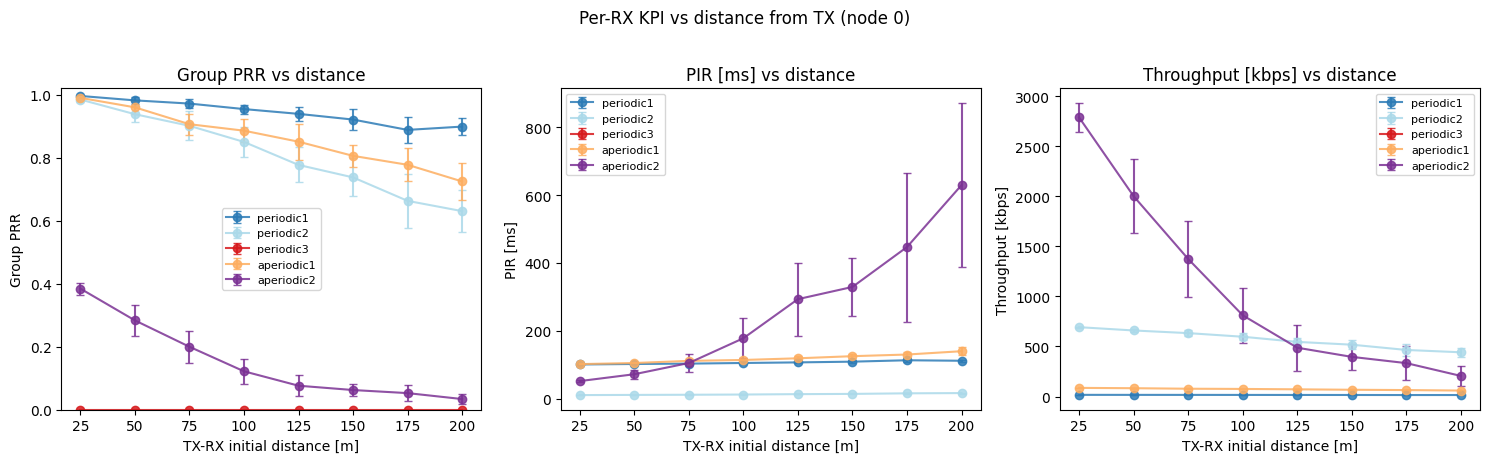

In [13]:
metrics = [('prr', 'Group PRR', (0, 1.02)),
           ('pir_ms', 'PIR [ms]', None),
           ('tput_kbps', 'Throughput [kbps]', None)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, label, ylim) in zip(axes, metrics):
    for c in classes:
        sub = rx[rx.trafficClass == c]
        grp = sub.groupby('rx_node_id').agg(
            d=('init_dist_m','mean'), v=(col,'mean'), s=(col,'std')
        ).sort_values('d')
        ax.errorbar(grp.d, grp.v, yerr=grp.s, fmt='o-',
                    color=CLASS_COLORS[c], capsize=3, lw=1.5, label=c, alpha=0.85)
    ax.set_xlabel('TX-RX initial distance [m]'); ax.set_ylabel(label)
    if ylim: ax.set_ylim(ylim)
    ax.set_title(f'{label} vs distance'); ax.legend(fontsize=8)
fig.suptitle('Per-RX KPI vs distance from TX (node 0)', y=1.02)
fig.tight_layout(); plt.show()

## 4. Per-RX time-series variation

Mean PRR over 1-s windows, averaged across seeds. Each line is one RX node (colour = distance order).

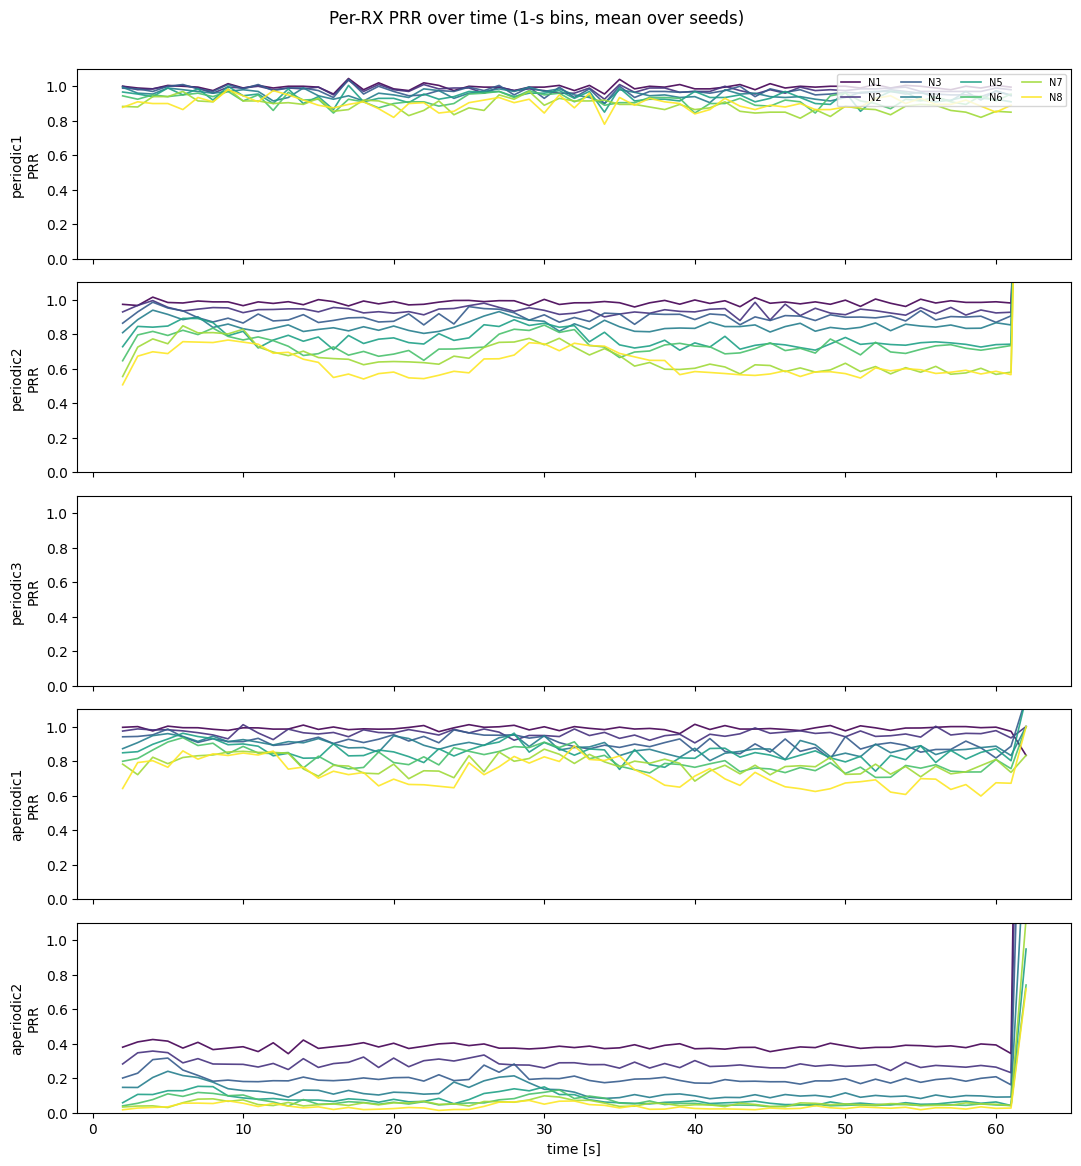

In [14]:
rx_nodes = sorted(ts.rx_node_id.unique())
cmap = plt.get_cmap('viridis')
fig, axes = plt.subplots(len(classes), 1,
                         figsize=(11, 2.3*len(classes)),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes)
for ax, c in zip(axes, classes):
    sub = ts[ts.trafficClass == c]
    for j, nid in enumerate(rx_nodes):
        ss = sub[sub.rx_node_id == nid]
        if ss.empty: continue
        agg = ss.groupby('t_bin_s').prr_window.mean()
        ax.plot(agg.index, agg.values,
                color=cmap(j/max(1,len(rx_nodes)-1)),
                lw=1.2, label=f'N{nid}', alpha=0.9)
    ax.set_ylabel(f'{c}\nPRR'); ax.set_ylim(0, 1.1)
axes[-1].set_xlabel('time [s]')
axes[0].legend(fontsize=7, ncol=4, loc='upper right')
fig.suptitle('Per-RX PRR over time (1-s bins, mean over seeds)', y=1.01)
fig.tight_layout(); plt.show()

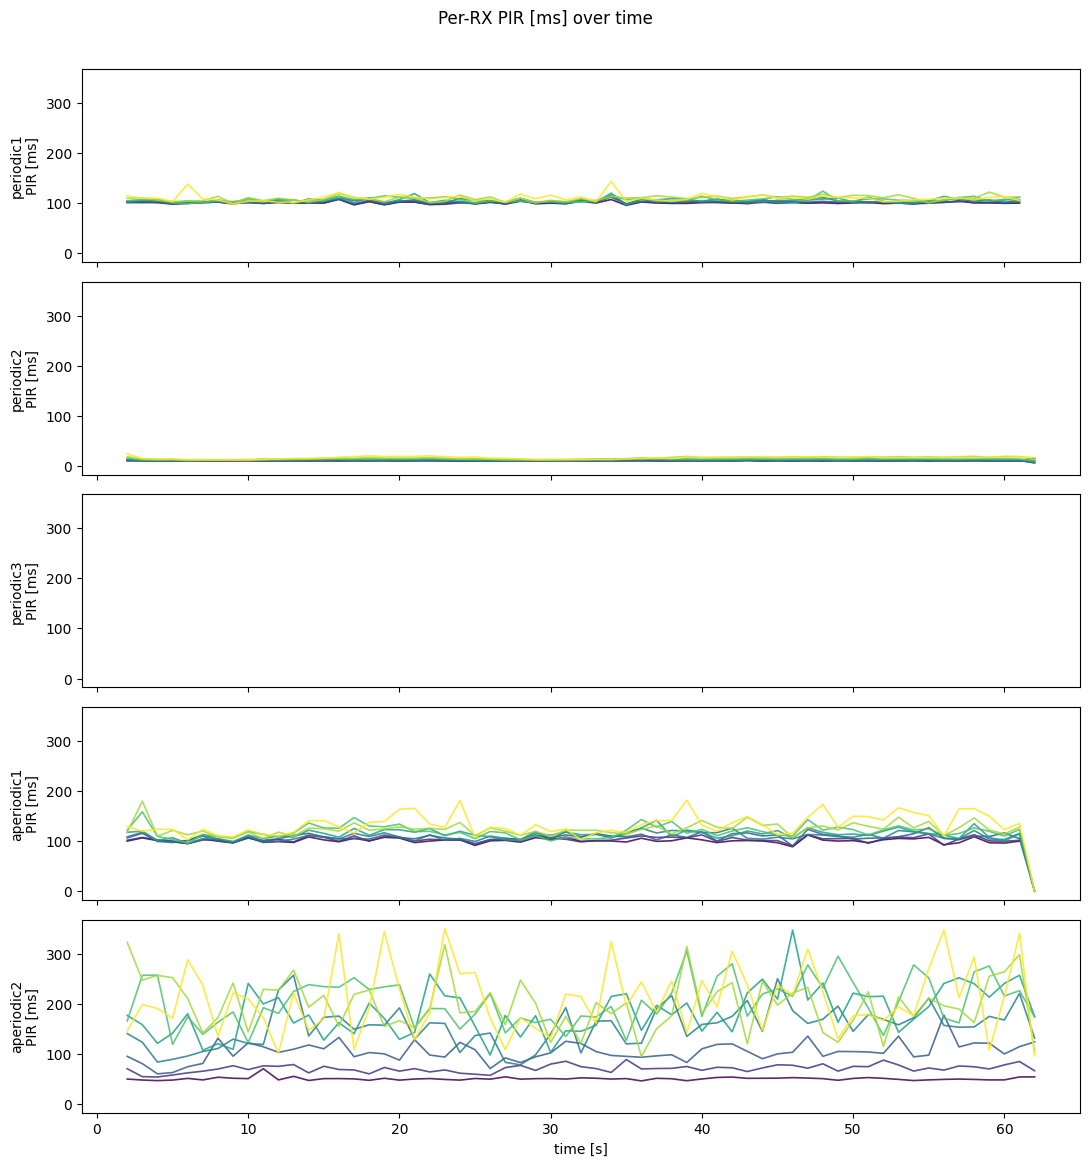

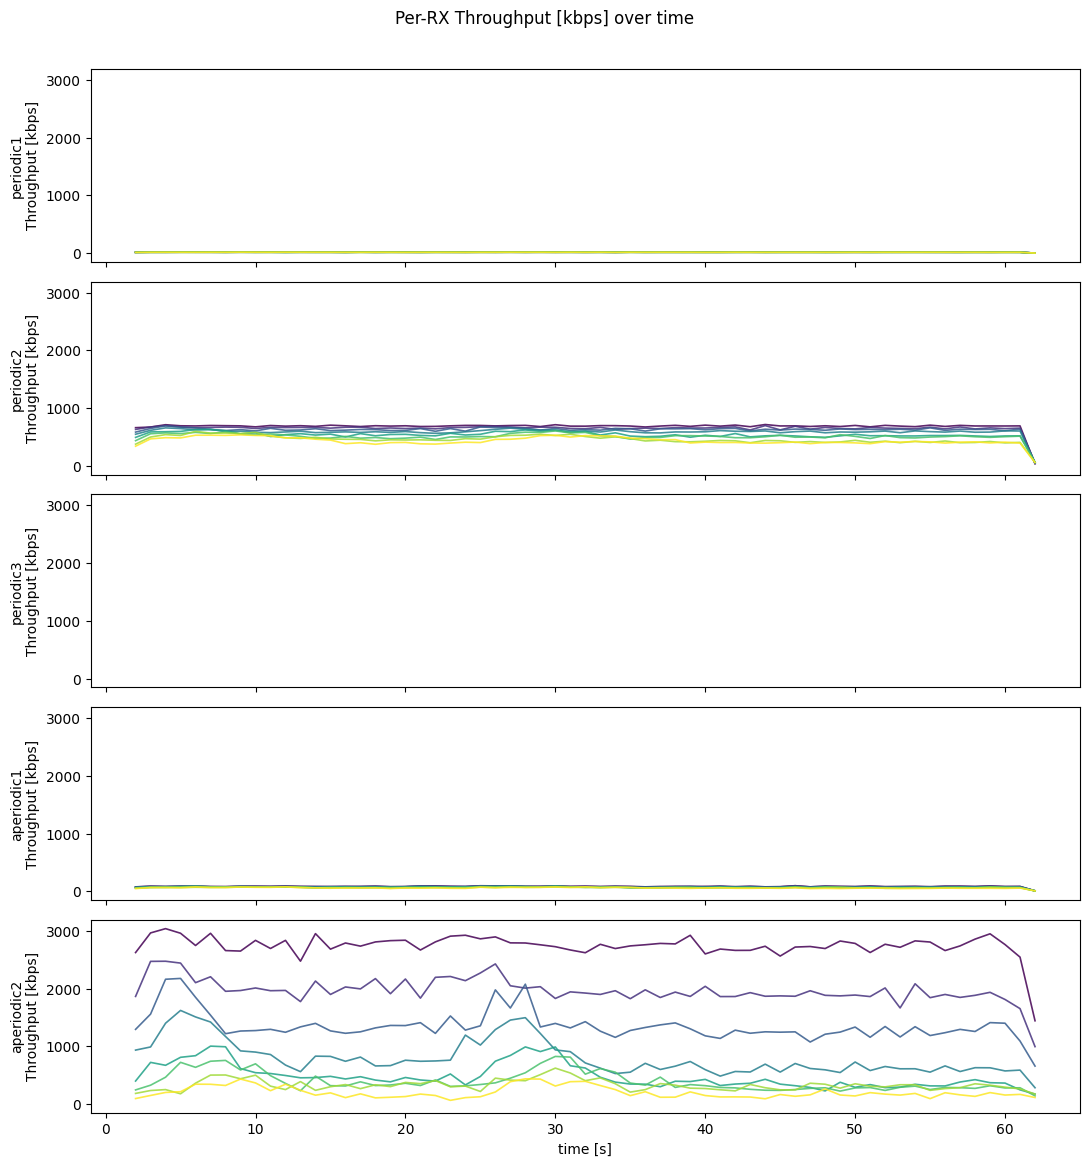

In [15]:
# PIR and throughput time-series
for kpi_col, ylab in [('pir_window_ms','PIR [ms]'), ('tput_window_kbps','Throughput [kbps]')]:
    fig, axes = plt.subplots(len(classes), 1,
                             figsize=(11, 2.3*len(classes)),
                             sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, classes):
        sub = ts[ts.trafficClass == c]
        for j, nid in enumerate(rx_nodes):
            ss = sub[sub.rx_node_id == nid]
            if ss.empty: continue
            agg = ss.groupby('t_bin_s')[kpi_col].mean()
            ax.plot(agg.index, agg.values,
                    color=cmap(j/max(1,len(rx_nodes)-1)),
                    lw=1.2, alpha=0.85)
        ax.set_ylabel(f'{c}\n{ylab}')
    axes[-1].set_xlabel('time [s]')
    fig.suptitle(f'Per-RX {ylab} over time', y=1.01)
    fig.tight_layout(); plt.show()

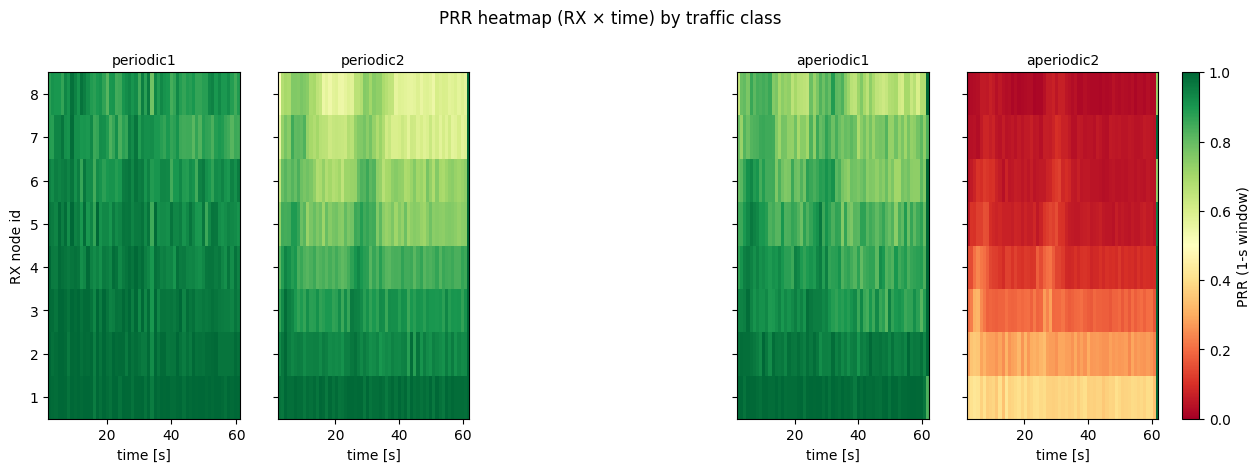

In [16]:
# Heatmap (RX × time) of PRR per class
fig, axes = plt.subplots(1, len(classes),
                         figsize=(3.0*len(classes), 4.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, c in zip(axes, classes):
    sub = ts[ts.trafficClass == c]
    if sub.empty:
        ax.set_visible(False); continue
    piv = sub.pivot_table(index='rx_node_id', columns='t_bin_s',
                          values='prr_window', aggfunc='mean')
    im = ax.imshow(piv.values, aspect='auto', vmin=0, vmax=1,
                   cmap='RdYlGn', origin='lower',
                   extent=[piv.columns.min(), piv.columns.max(),
                           piv.index.min()-0.5, piv.index.max()+0.5])
    ax.set_title(c, fontsize=10); ax.set_xlabel('time [s]')
    ax.set_yticks(sorted(ts.rx_node_id.unique()))
axes[0].set_ylabel('RX node id')
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02).set_label('PRR (1-s window)')
fig.suptitle('PRR heatmap (RX × time) by traffic class', y=1.02)
plt.show()

## 5. Resource usage

Per-class allocation footprint: PRB length histogram, total grant count per run, and retransmission share.

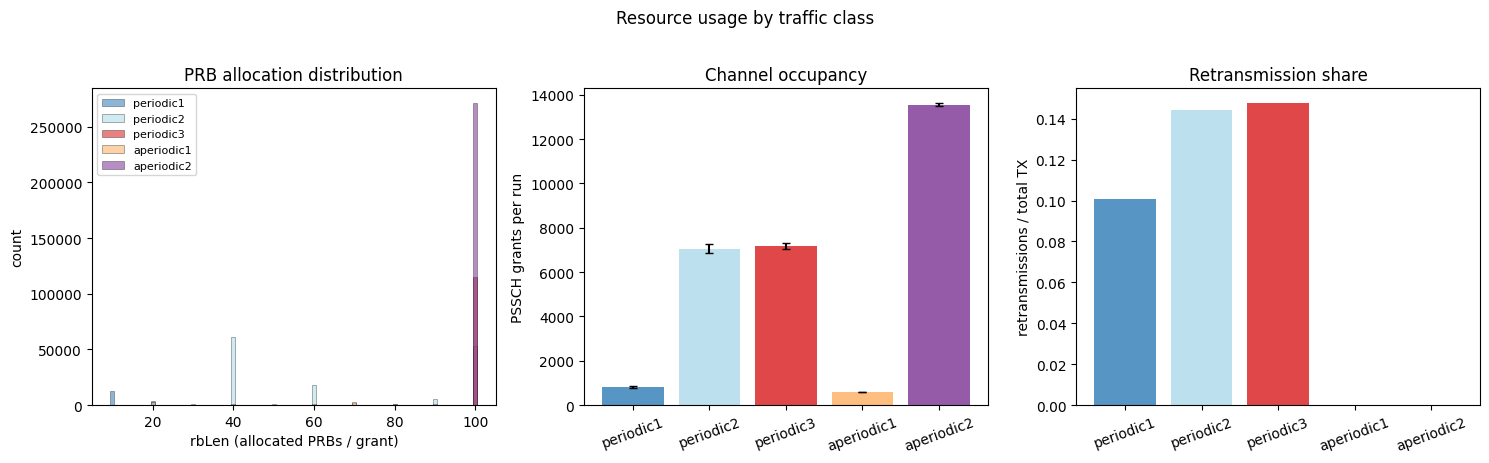

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ax = axes[0]
for c in classes:
    vals = ru[ru.trafficClass == c]['rbLen'].to_numpy()
    if len(vals) == 0: continue
    bins = np.arange(vals.min(), vals.max()+2) - 0.5
    ax.hist(vals, bins=bins, alpha=0.55, label=c,
            color=CLASS_COLORS[c], edgecolor='black', lw=0.4)
ax.set_xlabel('rbLen (allocated PRBs / grant)'); ax.set_ylabel('count')
ax.set_title('PRB allocation distribution'); ax.legend(fontsize=8)

ax = axes[1]
grp = (ru.groupby(['trafficClass','seed']).size().reset_index(name='n_grants'))
means = grp.groupby('trafficClass').n_grants.agg(['mean','std']).reindex(classes)
ax.bar(range(len(classes)), means['mean'], yerr=means['std'],
       color=[CLASS_COLORS[c] for c in classes], alpha=0.8, capsize=3)
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=20)
ax.set_ylabel('PSSCH grants per run'); ax.set_title('Channel occupancy')

ax = axes[2]
retx = []
for c in classes:
    sub = ru[ru.trafficClass == c]
    retx.append((sub.ndi == 0).sum() / max(1, len(sub)))
ax.bar(range(len(classes)), retx,
       color=[CLASS_COLORS[c] for c in classes], alpha=0.8)
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=20)
ax.set_ylabel('retransmissions / total TX'); ax.set_title('Retransmission share')
fig.suptitle('Resource usage by traffic class', y=1.02); fig.tight_layout(); plt.show()

## 6. HARQ statistics

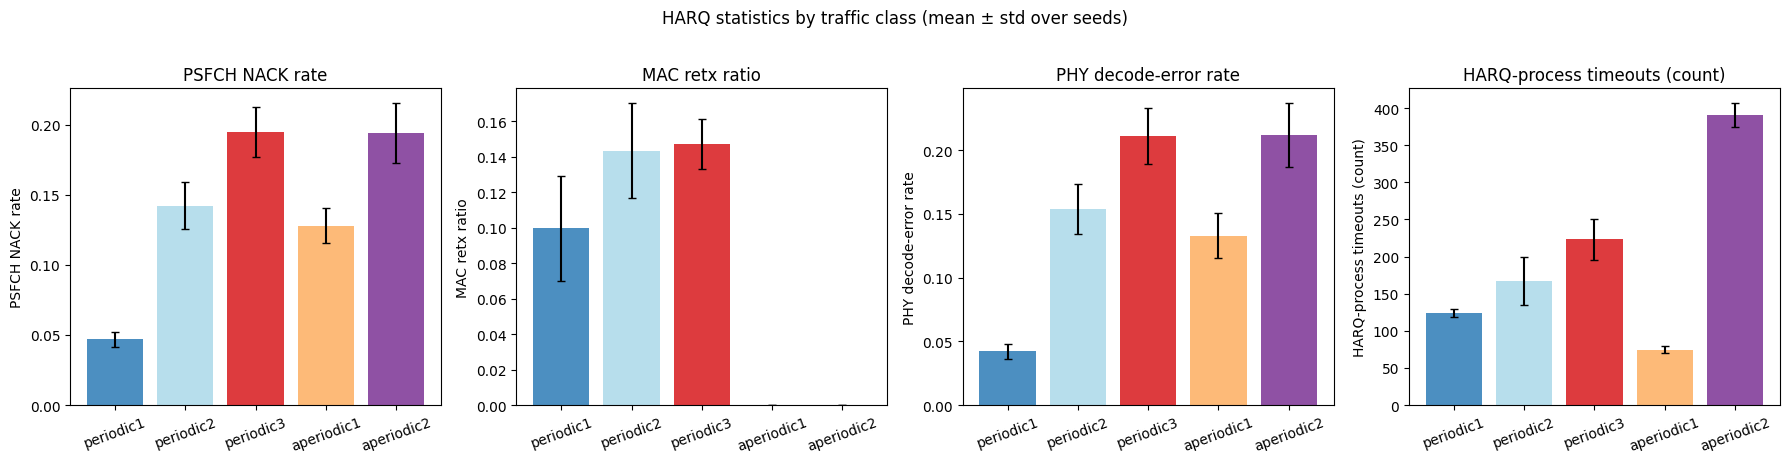

In [18]:
metrics = [('nack_rate', 'PSFCH NACK rate'),
           ('retx_ratio', 'MAC retx ratio'),
           ('phy_err_rate', 'PHY decode-error rate'),
           ('timeout_count', 'HARQ-process timeouts (count)')]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (col, label) in zip(axes, metrics):
    agg = hq.groupby('trafficClass')[col].agg(['mean','std']).reindex(classes)
    ax.bar(range(len(classes)), agg['mean'], yerr=agg['std'],
           color=[CLASS_COLORS[c] for c in classes], alpha=0.85, capsize=3)
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=20)
    ax.set_ylabel(label); ax.set_title(label)
fig.suptitle('HARQ statistics by traffic class (mean ± std over seeds)', y=1.02)
fig.tight_layout(); plt.show()

## 7. Summary table

Group-level summary ranking classes by mean group PRR.

In [19]:
summary = rx.groupby('trafficClass').agg(
    prr_mean        = ('prr','mean'),
    prr_min         = ('prr','min'),
    prr_max         = ('prr','max'),
    prr_p5          = ('prr', lambda s: s.quantile(0.05)),
    pir_mean_ms     = ('pir_ms','mean'),
    pir_p95_ms      = ('pir_ms', lambda s: s.quantile(0.95)),
    tput_mean_kbps  = ('tput_kbps','mean'),
    tput_p5_kbps    = ('tput_kbps', lambda s: s.quantile(0.05)),
    n_seeds         = ('seed','nunique'),
).join(hq.groupby('trafficClass')[['nack_rate','retx_ratio','phy_err_rate']].mean())
summary = summary.reindex(classes)
summary.style.format(precision=3).background_gradient(subset=['prr_mean','prr_p5'], cmap='RdYlGn', vmin=0, vmax=1)

,prr_mean,prr_min,prr_max,prr_p5,pir_mean_ms,pir_p95_ms,tput_mean_kbps,tput_p5_kbps,n_seeds,nack_rate,retx_ratio,phy_err_rate
trafficClass,,,,,,,,,,,,
periodic1,0.944,0.766,1.000,0.864,106.221,115.693,15.943,14.597,20,0.047,0.100,0.042
periodic2,0.810,0.510,0.994,0.578,12.733,17.337,569.405,404.261,20,0.142,0.144,0.154
periodic3,0.000,0.000,0.000,0.000,nan,nan,nan,nan,20,0.195,0.147,0.211
aperiodic1,0.862,0.573,0.998,0.694,118.002,143.413,73.451,58.277,20,0.128,0.000,0.133
aperiodic2,0.152,0.013,0.406,0.024,263.017,712.180,1049.778,143.440,20,0.194,0.000,0.212


## 8. Throughput-efficiency derived metric

Compare measured RX throughput against the *offered* throughput each `CustomTrafficApplication` mode would generate in steady state. Offered values from `groupcast_flows.h` definitions:

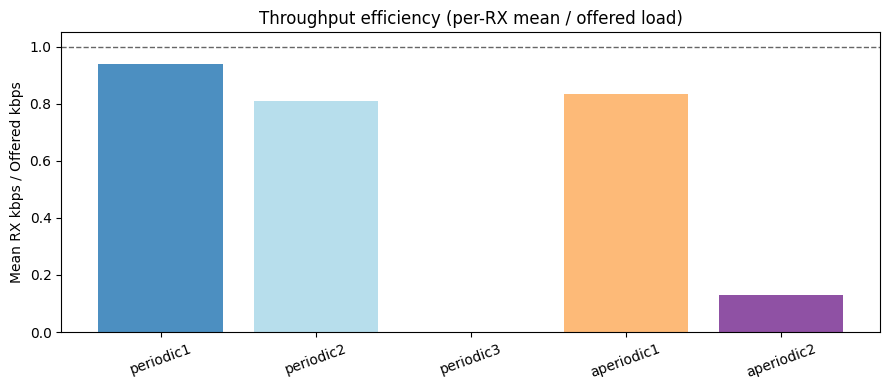

Offered loads (kbps):
  periodic1          17.0
  periodic2         704.0
  periodic3       12000.0
  aperiodic1         88.0
  aperiodic2       8000.0
Efficiencies:
  periodic1         0.940
  periodic2         0.809
  periodic3           nan
  aperiodic1        0.835
  aperiodic2        0.131


In [20]:
# Offered load per class (mean kbps the application would generate)
# Derived from comments in scratch_overlay/csi_groupcast_eval/groupcast_flows.h:
#   Periodic1: 100 ms, mean size = (300+190*4)/5 = 212 B → 16.96 kbps
#   Periodic2: 10 ms, mean = 0.8*800 + 0.2*1200 = 880 B → 704 kbps
#   Periodic3: 30 ms, mean = (30000+60000)/2 = 45 kB → 12 000 kbps
#   Aperiodic1: 50+Exp(50)=100ms mean, mean size = (200+2000)/2 = 1100 B → 88 kbps
#   Aperiodic2: 10+Exp(10)=20ms mean, mean size = (10000+30000)/2 = 20 kB → 8 000 kbps
OFFERED_KBPS = {
    'periodic1':   16.96,
    'periodic2':  704.0,
    'periodic3': 12000.0,
    'aperiodic1':  88.0,
    'aperiodic2': 8000.0,
}
eff = (rx.groupby('trafficClass').tput_kbps.mean()
         / pd.Series(OFFERED_KBPS)).rename('efficiency')
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(classes)), [eff[c] for c in classes],
       color=[CLASS_COLORS[c] for c in classes], alpha=0.85)
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=20)
ax.set_ylabel('Mean RX kbps / Offered kbps')
ax.set_title('Throughput efficiency (per-RX mean / offered load)')
ax.axhline(1.0, color='0.4', ls='--', lw=1)
fig.tight_layout(); plt.show()

print('Offered loads (kbps):')
for c in classes: print(f'  {c:<11s}  {OFFERED_KBPS.get(c, float("nan")):>10.1f}')
print('Efficiencies:')
for c in classes: print(f'  {c:<11s}  {eff.get(c, float("nan")):>10.3f}')

## Interpretation hints

- **Small periodic** (`periodic1`, ~17 kbps offered) is the lightest load — high PRR everywhere is expected; the geometric NLOSv only hurts far RXs when shadowing has them deep below sensitivity.
- **Large periodic** (`periodic3`, ~12 Mb/s offered, 30-60 kB bursts) and **large aperiodic** (`aperiodic2`, ~8 Mb/s, 10-30 kB bursts) saturate the pool: high `retx_ratio` and `nack_rate` are signatures of multiplexing-limited delivery.
- A near-monotonic PRR drop with distance for every class confirms the NLOSv-driven attenuation; classes differ in *slope*, not in whether the drop occurs.
- `pir_window_ms` spikes co-occurring with PRR dips identify *temporary outages* — useful to align with the platoon's geometry (corner turn near t≈30 s in this trace).